# COU 07506 – DIGITAL SIGNAL PROCESSING

## LAB 0: Setting Up the DSP Laboratory

**Student:** Rahel Bryson Faustine

**Topic:** Introduction to Discrete-Time Signals

**Environment:** Google Colab

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile

plt.rcParams["figure.figsize"] = (9, 3.5)

print("DSP Laboratory Environment Ready!")

DSP Laboratory Environment Ready!


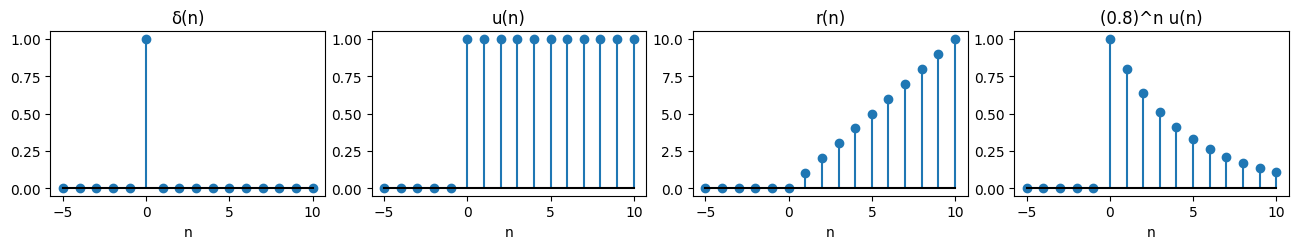

In [ ]:
# Define the sample index
n = np.arange(-5, 11)

# Generate elementary signals
delta = (n == 0).astype(float)  # Unit impulse
step = (n >= 0).astype(float)   # Unit step
ramp = n * step                 # Unit ramp
expo = 0.8**n * step            # Real exponential

# Plot the four signals
fig, axes = plt.subplots(1, 4, figsize=(13, 2.6))

for ax, x, title in zip(
    axes,
    [delta, step, ramp, expo],
    ["δ(n)", "u(n)", "r(n)", "(0.8)^n u(n)"]
):
    ax.stem(n, x, basefmt="k-")
    ax.set_title(title)
    ax.set_xlabel("n")

plt.tight_layout()
plt.show()

Task 1.2 — Change the Parameters

Part (a): Plot exponential signals

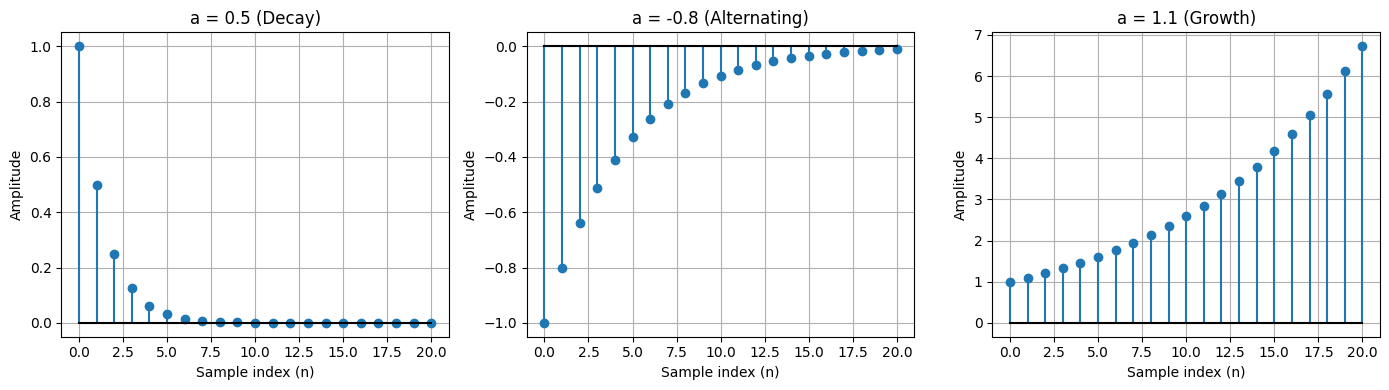

In [ ]:
# Generate the sample index
n = np.arange(0, 21)

# Generate the unit step signal
u = (n >= 0).astype(float)

# Generate exponential signals
x1 = (0.5**n) * u
x2 = (-0.8**n) * u
x3 = (1.1**n) * u

# Create subplots
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

signals = [x1, x2, x3]
titles = ["a = 0.5 (Decay)",
          "a = -0.8 (Alternating)",
          "a = 1.1 (Growth)"]

# Plot each signal
for ax, x, title in zip(axes, signals, titles):
    ax.stem(n, x, basefmt="k-")
    ax.set_title(title)
    ax.set_xlabel("Sample index (n)")
    ax.set_ylabel("Amplitude")
    ax.grid(True)

plt.tight_layout()
plt.show()

In this experiment, three exponential discrete-time signals were generated using different values of the parameter \(a\).
- For \(a=0.5\), the signal decreases exponentially towards zero as the sample index increases. This is called exponential decay.
- For \(a=-0.8\), the signal alternates between positive and negative values while its magnitude gradually decreases towards zero.
- For \(a=1.1\), the signal increases exponentially as the sample index increases. This is called exponential growth.
The experiment demonstrates how changing the value and sign of the parameter \(a\) affects the behaviour of an exponential discrete-time signal.

Part (b): Plot cosine signals

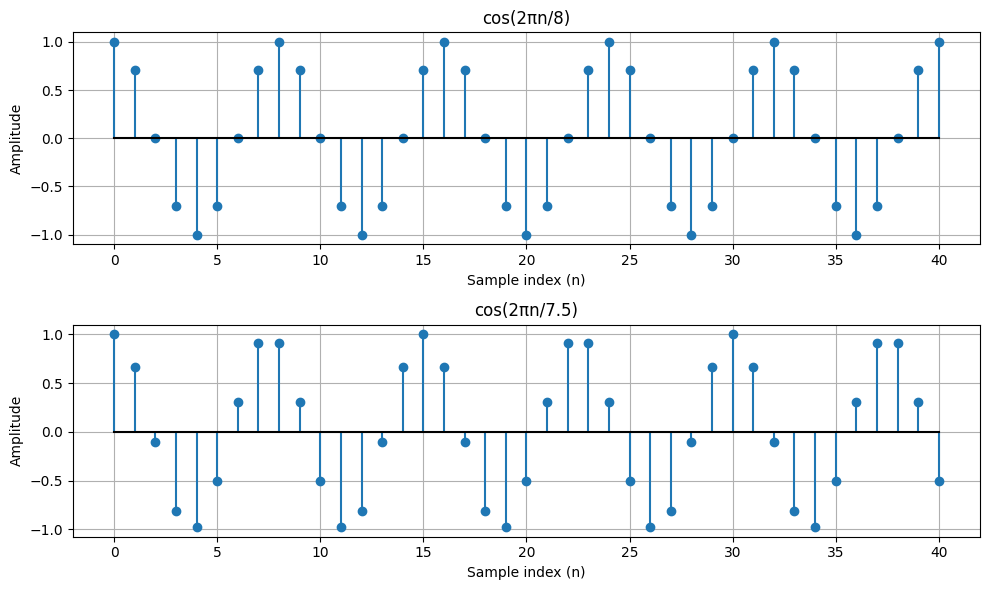

In [ ]:
# Generate sample indices from 0 to 40
n = np.arange(0, 41)

# Generate cosine signals
x1 = np.cos(2 * np.pi * n / 8)
x2 = np.cos(2 * np.pi * n / 7.5)

# Create two subplots
fig, axes = plt.subplots(2, 1, figsize=(10, 6))

# Plot first cosine signal
axes[0].stem(n, x1, basefmt="k-")
axes[0].set_title("cos(2πn/8)")
axes[0].set_xlabel("Sample index (n)")
axes[0].set_ylabel("Amplitude")
axes[0].grid(True)

# Plot second cosine signal
axes[1].stem(n, x2, basefmt="k-")
axes[1].set_title("cos(2πn/7.5)")
axes[1].set_xlabel("Sample index (n)")
axes[1].set_ylabel("Amplitude")
axes[1].grid(True)

plt.tight_layout()
plt.show()

Explanation

Two discrete-time cosine signals were generated and plotted for sample indices ranging from 0 to 40.

The first signal, *cos(2πn/8)*, repeats its pattern after every 8 samples.

The second signal, *cos(2πn/7.5)*, repeats its pattern after every 15 samples.

Therefore, both signals are periodic discrete-time signals, although they have different fundamental periods.
Conclusion
The experiment demonstrates that the periodicity of a discrete-time cosine signal depends on its normalized frequency.
Both signals repeat exactly, with periods of 8 and 15 samples, respectively.

Sampling frequency = 48000 Hz
Duration = 5.67 seconds
Number of samples = 272384


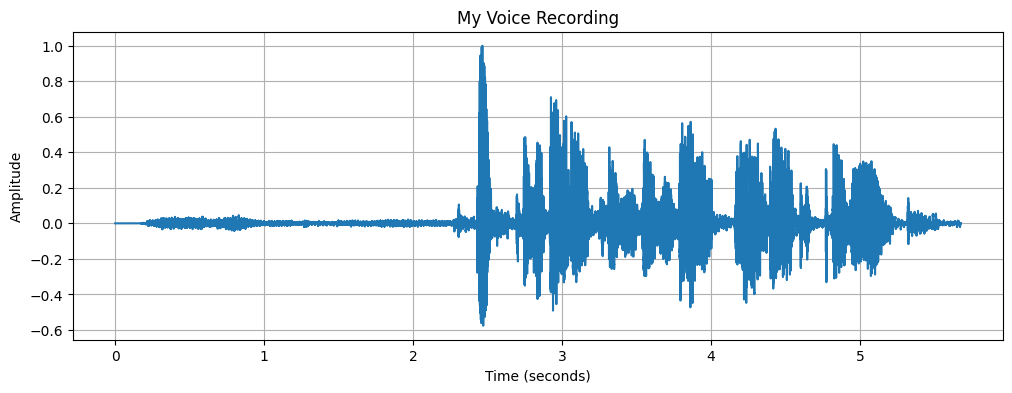

In [ ]:
import os

fname = "voice.wav"

if os.path.exists(fname):
    fs, x = wavfile.read(fname)

    # Convert stereo audio to mono
    if x.ndim > 1:
        x = x.mean(axis=1)

    # Normalize the audio
    x = x / np.max(np.abs(x))

else:
    # Generate a test signal if no recording is found
    fs = 16000
    t = np.arange(0, 2, 1/fs)
    x = 0.5 * np.sin(2*np.pi*440*t) * np.exp(-t)

# Generate time axis
t = np.arange(len(x)) / fs

# Display audio information
print(f"Sampling frequency = {fs} Hz")
print(f"Duration = {len(x)/fs:.2f} seconds")
print(f"Number of samples = {len(x)}")

# Plot audio waveform
plt.figure(figsize=(12, 4))
plt.plot(t, x)
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.title("My Voice Recording")
plt.grid(True)
plt.show()

**Explanation: Voice Signal Plot**

The time axis is generated using the number of audio samples divided by the sampling frequency. This gives the time corresponding to each sample.

The recorded voice signal is plotted with time (seconds) on the horizontal axis and amplitude on the vertical axis.

The waveform represents how the amplitude of the recorded voice changes over time. Regions with larger amplitude indicate stronger sound intensity, while regions with smaller amplitude indicate quieter sounds or pauses.

This plot provides a visual representation of the recorded speech signal in the time domain.

In [ ]:
from IPython.display import Audio

Audio(x, rate=fs)

**Observation**

The recorded voice signal is a non-periodic audio signal because speech does not repeat in exactly the same pattern over fixed time intervals. Its amplitude varies with spoken words, pauses, and changes in voice intensity.

**Conclusion**

The practical demonstrated how to load a recorded audio signal, obtain its sampling frequency and duration, convert stereo audio to mono when necessary, normalize the signal, visualize its waveform in the time domain, and play it back using Python.

In [ ]:
# Convert stereo audio to mono if necessary
if x.ndim > 1:
    x = x.mean(axis=1)

# Normalize the audio signal
peak = np.max(np.abs(x))

if peak > 0:
    x = x / peak

print("Audio prepared successfully.")
print("Final number of samples:", len(x))

Audio prepared successfully.
Final number of samples: 272384


The recording is converted to mono if it contains two audio channels (stereo). This is achieved by calculating the average of the left and right channels. The signal is then normalized by dividing each sample by the maximum absolute amplitude.

Normalization scales the signal amplitude to a range of approximately -1 to +1 without changing its overall waveform shape.

Analysis Questions

Question 1: What is the sampling rate of your phone recording? How many numbers are required to store one minute of mono audio?

In [ ]:
# Number of samples in one minute of mono audio
samples_per_minute = fs * 60

print("Sampling frequency:", fs, "Hz")
print("Samples required for one minute:", samples_per_minute)

Sampling frequency: 48000 Hz
Samples required for one minute: 2880000


### 1. What is the sampling rate of your phone recording? How many numbers are required to store one minute of mono audio?

**Answer:**

From my recorded voice signal, the following parameters were obtained:

- Sampling frequency ($f_s$): **48,000 Hz**
- Recording duration: **5.67 seconds**
- Number of samples: **272,384**

The sampling frequency indicates that the recording captures 48,000 samples per second.

The number of samples required to store one minute of mono audio is calculated using:

$$
N = f_s \times T
$$

Where:

- $N$ = Total number of samples
- $f_s$ = Sampling frequency
- $T$ = Duration in seconds

For one minute of audio:

$$
N = 48,000 \times 60
$$

$$
\boxed{N = 2,880,000 \text{ samples}}
$$

**Conclusion:**

Therefore, one minute of mono audio recorded at a sampling frequency of 48,000 Hz requires **2,880,000 audio samples**.

This means that the number of samples required increases with the sampling frequency and recording duration.

#### 2. Why is a stem plot better than a continuous line plot for representing $x(n)$?

**Answer:**

A stem plot is more appropriate for representing discrete-time signals because it displays individual samples at specific integer time indices.

Each sample is represented by a vertical line (stem) and a marker showing its amplitude. This makes it easier to identify the individual values of the discrete-time signal.

In contrast, a continuous line plot connects adjacent samples, which may create the impression that the signal exists at every point in time.

**Conclusion:**

A stem plot provides a more accurate visual representation of discrete-time signals because it clearly shows that the signal is defined only at discrete sampling instants.

### 3. For $a = 1.1$, the exponential signal grows. Which system property would such a signal violate if it were an impulse response?

**Answer:**

The system property that would be violated is **Bounded-Input Bounded-Output (BIBO) stability**.

For a discrete-time Linear Time-Invariant (LTI) system to be BIBO stable, its impulse response must be absolutely summable.

The stability condition is expressed as:

$$
\sum_{n=-\infty}^{\infty} |h(n)| < \infty
$$

For the given exponential signal:

$$
h(n) = 1.1^n u(n)
$$

Since the exponential base is greater than one ($a = 1.1$), the signal increases exponentially as the sample index $n$ increases.

Consequently, the sum of the absolute values of the impulse response approaches infinity:

$$
\sum_{n=0}^{\infty} 1.1^n = \infty
$$

Therefore, the impulse response is not absolutely summable.

**Conclusion:**

A system with this impulse response is not BIBO stable because it does not satisfy the absolute summability condition required for stability.

### Task 1.4: Results from GNU Octave

The elementary discrete-time signals were successfully generated and plotted using GNU Octave 11.3.0.

The following signals were implemented:

1. Unit impulse signal
2. Unit step signal
3. Unit ramp signal
4. Exponential signal

The `stem()` function was used to visualize the individual samples of each discrete-time signal. The generated figures were saved in PNG format and inserted into the Google Colab notebook.

**Observation:**

The graphical results obtained using GNU Octave are consistent with those obtained using Python in Task 1.1. Both programming environments successfully generated and visualized the elementary discrete-time signals.

**Conclusion:**

Task 1.4 demonstrated the use of GNU Octave for basic digital signal processing operations and provided an opportunity to compare its syntax and plotting functions with Python.

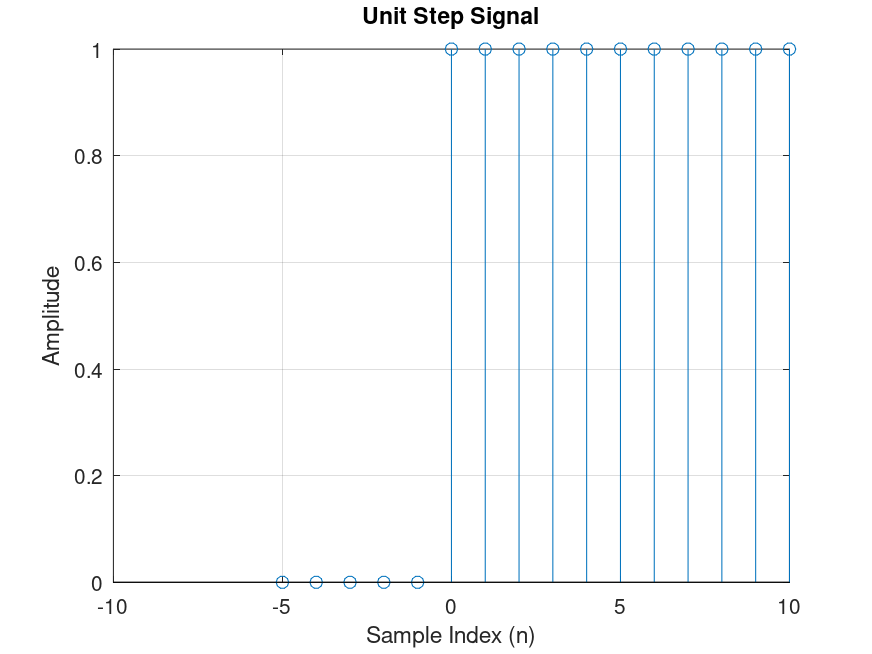

In [4]:
from IPython.display import Image, display

# Display unit step graph
display(Image(filename='Unit_Step1.png'))


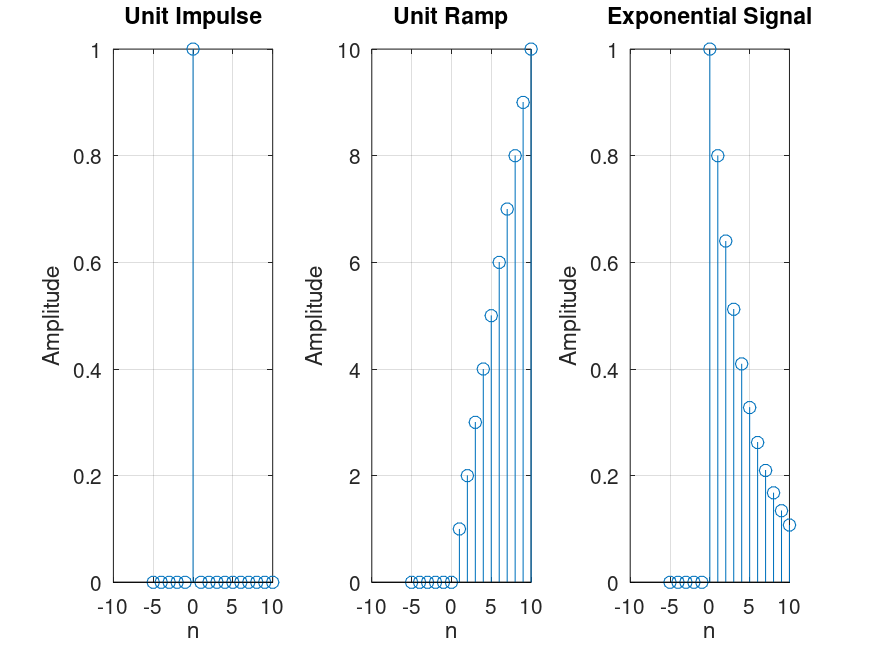

In [5]:
from IPython.display import Image, display


# Display the other elementary signals
display(Image(filename='Elementary_Signals.png'))